# Modelos: riesgo de adición en contratos de obra pública (SECOP II)

**Pregunta de negocio.** ¿Qué contratos de obra pública firmados en SECOP II
tienen mayor probabilidad de recibir adiciones en tiempo o en valor durante su
ejecución, usando solo información disponible al momento de la firma, para que
la DIARI y las veedurías prioricen su seguimiento preventivo?

**Tarea.** Clasificación binaria supervisada. `y = 1` si el contrato registra
adición en tiempo (`dias_adicionados > 0`) o en valor (tabla Adiciones, tipo
"Adicion en el valor"). `y_tiempo` e `y_valor` son sus dos componentes.

**Procedimiento.**

1. Tabla de modelado: `src/features.py`, con las reglas del EDA
   (`notebooks/01_eda_obra.ipynb`, sección 17).
2. Modelos, validación y métricas: `src/modelo.py`.
3. Se comparan cuatro modelos (regresión logística, Random Forest, LightGBM y
   CatBoost) con el mismo preprocesamiento.
4. Selección del modelo y de las variables con validación temporal de
   ventana creciente (2022, 2023 y 2024) y prueba única en 2025.
5. Los experimentos se registran en MLflow con las mismas funciones
   (`validar`, `buscar`, `entrenar`); las cifras de este notebook coinciden
   con las corridas registradas porque las semillas son fijas.

## 1. Configuración

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_recall_curve

sys.path.insert(0, "../src")
from features import (CATEGORICAS, ENTIDAD, NUMERICAS,  # noqa: E402
                      OBJETIVOS, VARIABLES, cargar)
from modelo import (GANADOR, MODELOS, PLIEGUES, PRUEBA,  # noqa: E402
                    REJILLAS, SEMILLA, aportes, buscar, entrenar,
                    pipeline, validar)

warnings.filterwarnings("ignore", message="X does not have valid feature")
FIG = Path("../reports/figures")
NOMBRES = {"logistica": "Regresión logística",
           "random_forest": "Random Forest", "lightgbm": "LightGBM",
           "catboost": "CatBoost"}
PRINCIPALES = ["pr_auc", "roc_auc", "precision_100", "precision_10pct",
               "recall_10pct", "lift_10pct", "brier"]
ETIQUETAS = {
    "log_valor_inicial": "Valor inicial (log)",
    "plazo_inicial": "Plazo inicial", "respuestas": "Respuestas al proceso",
    "inicial_sobre_base": "Valor inicial / precio base",
    "dias_publicacion_adjudicacion": "Días publicación a adjudicación",
    "previos_entidad": "Contratos previos de la entidad",
    "antiguedad_prov": "Antigüedad del proveedor",
    "proceso_compartido": "Proceso compartido (lotes)",
    "proveedor_repetido": "Proveedor repetido con la entidad",
    "nombre_entidad": "Entidad", "modalidad": "Modalidad",
    "departamento": "Departamento", "segmento_unspsc": "Segmento UNSPSC",
    "fuente_principal": "Fuente principal de recursos",
    "destino_gasto": "Destino del gasto",
    "condiciones_de_entrega": "Condiciones de entrega", "es_pyme": "Pyme",
    "tipodocproveedor": "Tipo de documento del proveedor",
    "mes": "Mes de firma",
}
FINAL = dict(params=GANADOR["params"], excluir=GANADOR["excluir"])
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format


def guardar_figura(nombre):
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=150)
    plt.show()


def resumir(metricas):
    """Media y desviación entre pliegues de las métricas principales."""
    m = metricas[PRINCIPALES]
    return (m.mean().map("{:.3f}".format) + " ± "
            + m.std().map("{:.3f}".format))

## 2. Datos y partición

1. Se carga la tabla de modelado: contratos de obra firmados entre 2019 y
   2025, sin los que tienen el plazo inicial vigente a la fecha de descarga.
2. Se describen las tasas de cada objetivo por año.
3. La partición es temporal: cada pliegue entrena con los años anteriores al
   año evaluado. 2025 se reserva como prueba y no se usa para elegir.

In [2]:
datos = cargar()
print(f"Contratos: {len(datos):,}")
print(datos.groupby("anio").agg(
    contratos=("y", "size"), y=("y", "mean"), y_tiempo=("y_tiempo", "mean"),
    y_valor=("y_valor", "mean")).to_string())

anios = PLIEGUES + [PRUEBA]
print()
print(pd.DataFrame({
    "entrena": [f"2019-{a - 1}" for a in anios],
    "contratos de entrenamiento": [(datos["anio"] < a).sum() for a in anios],
    "evalúa": anios,
    "contratos evaluados": [(datos["anio"] == a).sum() for a in anios],
    "uso": ["validación"] * len(PLIEGUES) + ["prueba"],
}).to_string(index=False))

Contratos: 40,170
      contratos     y  y_tiempo  y_valor
anio                                    
2019       2291 0.353     0.135    0.242
2020       2757 0.346     0.201    0.176
2021       5393 0.347     0.261    0.111
2022       5954 0.338     0.252    0.106
2023       7944 0.297     0.227    0.089
2024       6468 0.349     0.280    0.087
2025       9363 0.470     0.425    0.079

  entrena  contratos de entrenamiento  evalúa  contratos evaluados        uso
2019-2021                       10441    2022                 5954 validación
2019-2022                       16395    2023                 7944 validación
2019-2023                       24339    2024                 6468 validación
2019-2024                       30807    2025                 9363     prueba


## 3. Variables y preprocesamiento

1. Se parte de 19 variables candidatas conocidas al firmar, seleccionadas en
   el EDA por su señal univariada (AUC), su cobertura y la ausencia de fuga.
   La sección 7 depura esta lista con el modelo seleccionado.
2. Se excluyen por fuga: estado, valor y duración actuales, fecha de fin,
   días adicionados, días entre firma e inicio, montos por fuente y variables
   de ejecución. Se excluyen por redundancia o falta de señal: proponentes,
   contratos previos del proveedor, orden, origen de los recursos, pago
   adelantado y justificación de la modalidad.
3. Preprocesamiento común a los cuatro modelos:
   1. Numéricas: imputación por mediana, indicador de faltante y escala.
   2. Entidad (2.370 categorías): tasa de adición suavizada con validación
      cruzada interna (`TargetEncoder`).
   3. Categóricas: one-hot; las categorías con menos de 50 contratos se
      agrupan y las desconocidas se tratan como infrecuentes.

In [3]:
tratamiento = pd.Series(
    {**{v: "numérica" for v in NUMERICAS},
     **{v: "tasa suavizada" for v in ENTIDAD},
     **{v: "one-hot" for v in CATEGORICAS}})
categorias = datos[VARIABLES].nunique().where(tratamiento != "numérica")
print(pd.DataFrame({
    "tratamiento": tratamiento,
    "% faltante": datos[VARIABLES].isna().mean() * 100,
    "categorías": categorias,
}).round(1).to_string())

entrena = datos[datos["anio"] < PRUEBA]
prep = pipeline(GANADOR["modelo"])["prep"].fit(entrena[VARIABLES],
                                               entrena["y"])
print(f"\nColumnas tras el preprocesamiento: "
      f"{len(prep.get_feature_names_out())}")

                                  tratamiento  % faltante  categorías
log_valor_inicial                    numérica       0.100         NaN
plazo_inicial                        numérica       9.700         NaN
respuestas                           numérica       0.000         NaN
inicial_sobre_base                   numérica      26.700         NaN
dias_publicacion_adjudicacion        numérica      29.100         NaN
previos_entidad                      numérica       0.000         NaN
antiguedad_prov                      numérica      32.800         NaN
proceso_compartido                   numérica       0.000         NaN
proveedor_repetido                   numérica       0.000         NaN
nombre_entidad                 tasa suavizada       0.000   2,370.000
modalidad                             one-hot       0.000       5.000
departamento                          one-hot       2.400      33.000
segmento_unspsc                       one-hot      16.100      54.000
fuente_principal    


Columnas tras el preprocesamiento: 108

## 4. Modelos base

1. Se entrenan los cuatro modelos con hiperparámetros iniciales razonables.
2. Se reporta la media y la desviación entre los tres pliegues temporales.

In [4]:
base = pd.DataFrame({NOMBRES[m]: resumir(validar(m, datos=datos))
                     for m in MODELOS}).T
print(base.to_string())

                            pr_auc        roc_auc  precision_100 precision_10pct   recall_10pct     lift_10pct          brier
Regresión logística  0.506 ± 0.031  0.696 ± 0.018  0.623 ± 0.085   0.585 ± 0.015  0.179 ± 0.015  1.791 ± 0.155  0.200 ± 0.011
Random Forest        0.518 ± 0.043  0.698 ± 0.031  0.760 ± 0.070   0.613 ± 0.033  0.187 ± 0.017  1.875 ± 0.172  0.198 ± 0.009
LightGBM             0.514 ± 0.034  0.698 ± 0.026  0.663 ± 0.064   0.614 ± 0.042  0.187 ± 0.015  1.875 ± 0.152  0.202 ± 0.013
CatBoost             0.519 ± 0.031  0.700 ± 0.024  0.697 ± 0.040   0.608 ± 0.029  0.186 ± 0.016  1.861 ± 0.155  0.200 ± 0.013


## 5. Ajuste de hiperparámetros

1. Búsqueda corta en rejilla (`REJILLAS` en `src/modelo.py`), 22
   configuraciones en total.
2. Cada configuración se evalúa en los tres pliegues temporales y se ordena
   por PR-AUC medio.

In [5]:
resultados, mejores = [], {}
for m in MODELOS:
    r = buscar(m, datos=datos)
    mejores[m] = r.iloc[0]["params"]
    resultados.append(r.assign(modelo=NOMBRES[m]))
busqueda = pd.concat(resultados)
busqueda["configuración"] = busqueda["params"].map(
    lambda p: ", ".join(f"{k}={v}" for k, v in p.items()))
print(busqueda[["modelo", "configuración", "pr_auc", "pr_auc_std",
                "roc_auc", "precision_100", "precision_10pct"]]
      .to_string(index=False))

             modelo                          configuración  pr_auc  pr_auc_std  roc_auc  precision_100  precision_10pct
Regresión logística                                 C=0.01   0.516       0.047    0.699          0.637            0.612
Regresión logística                                  C=0.1   0.508       0.033    0.697          0.643            0.591
Regresión logística                                    C=1   0.506       0.031    0.696          0.623            0.585
Regresión logística                                   C=10   0.505       0.031    0.696          0.617            0.585
      Random Forest  max_features=sqrt, min_samples_leaf=5   0.520       0.042    0.699          0.697            0.617
      Random Forest   max_features=0.3, min_samples_leaf=5   0.518       0.032    0.700          0.620            0.631
      Random Forest max_features=sqrt, min_samples_leaf=20   0.518       0.043    0.698          0.760            0.613
      Random Forest max_features=sqrt, m

## 6. Comparación y selección

1. Se compara la mejor configuración de cada modelo pliegue a pliegue.
2. Regla de selección: mayor PR-AUC medio. Los modelos cuya diferencia con
   el mejor es menor que la variación entre años (desviación de su PR-AUC)
   se consideran empatados, y entre ellos gana el de mayor precisión en 100
   en validación, que representa la capacidad de revisión de un veedor.
3. La selección se confirma con las corridas registradas en MLflow.

PR-AUC por pliegue:
        Regresión logística  Random Forest  LightGBM  CatBoost
evalua                                                        
2022                  0.486          0.503     0.504     0.508
2023                  0.493          0.489     0.498     0.516
2024                  0.570          0.567     0.553     0.550

                            pr_auc        roc_auc  precision_100 precision_10pct   recall_10pct     lift_10pct          brier
Regresión logística  0.516 ± 0.047  0.699 ± 0.024  0.637 ± 0.180   0.612 ± 0.039  0.187 ± 0.017  1.873 ± 0.167  0.199 ± 0.010
Random Forest        0.520 ± 0.042  0.699 ± 0.031  0.697 ± 0.153   0.617 ± 0.028  0.189 ± 0.013  1.886 ± 0.131  0.198 ± 0.009
LightGBM             0.518 ± 0.031  0.702 ± 0.022  0.663 ± 0.055   0.616 ± 0.026  0.188 ± 0.013  1.883 ± 0.127  0.199 ± 0.011
CatBoost             0.525 ± 0.022  0.704 ± 0.025  0.713 ± 0.078   0.621 ± 0.017  0.190 ± 0.012  1.898 ± 0.124  0.199 ± 0.013

Mayor PR-AUC medio: CatBoost (0.5

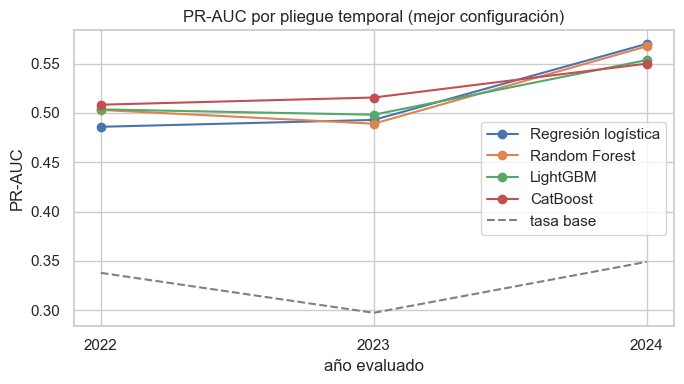

In [6]:
pliegues = {m: validar(m, params=mejores[m], datos=datos) for m in MODELOS}
pr = pd.DataFrame({m: r["pr_auc"] for m, r in pliegues.items()})
print("PR-AUC por pliegue:")
print(pr.rename(columns=NOMBRES).to_string())
print()
print(pd.DataFrame({NOMBRES[m]: resumir(r)
                    for m, r in pliegues.items()}).T.to_string())

media = pr.mean()
empatados = [m for m in MODELOS if media.max() - media[m] < pr[m].std()]
seleccion = max(empatados,
                key=lambda m: pliegues[m]["precision_100"].mean())
coincide = (seleccion == GANADOR["modelo"]
            and mejores[seleccion] == GANADOR["params"])
print(f"\nMayor PR-AUC medio: {NOMBRES[media.idxmax()]} "
      f"({media.max():.3f}). Empatados dentro de la variación entre años: "
      f"{', '.join(NOMBRES[m] for m in empatados)}.")
print(f"Seleccionado por precisión en 100: {NOMBRES[seleccion]} "
      f"{mejores[seleccion]}. Coincide con GANADOR: {coincide}")

fig, ax = plt.subplots(figsize=(7, 4))
for m in MODELOS:
    ax.plot(PLIEGUES, pr[m], marker="o", label=NOMBRES[m])
tasas = datos[datos["anio"].isin(PLIEGUES)].groupby("anio")["y"].mean()
ax.plot(PLIEGUES, tasas, ls="--", color="gray", label="tasa base")
ax.set(xticks=PLIEGUES, xlabel="año evaluado", ylabel="PR-AUC",
       title="PR-AUC por pliegue temporal (mejor configuración)")
ax.legend()
guardar_figura("13_comparacion_pliegues")

## 7. Selección de características

1. Con el modelo seleccionado se calcula la importancia por permutación
   (caída de PR-AUC, cinco repeticiones) en cada pliegue de validación y se
   promedia. 2025 no interviene.
2. Experimento de reducción: se quitan las variables con importancia media
   nula o negativa y se compara con el modelo completo en los tres pliegues.
3. Ablación de `fuente_principal`: los montos por fuente incluyen las
   adiciones (EDA, sección 13), por lo que la variable tiene riesgo de fuga.
   Se compara el modelo con y sin ella.
4. Regla: se quita una variable o grupo si el PR-AUC medio no baja de forma
   apreciable (menos de 0,005).

In [7]:
importancias = {}
for a in PLIEGUES:
    pipe_a, _ = entrenar(seleccion, params=mejores[seleccion], evalua=a,
                         datos=datos)
    ev = datos[datos["anio"] == a]
    r = permutation_importance(
        pipe_a, ev[VARIABLES], ev["y"], scoring="average_precision",
        n_repeats=5, random_state=SEMILLA, n_jobs=-1)
    importancias[a] = pd.Series(r.importances_mean, index=VARIABLES)
importancia_val = pd.DataFrame(importancias)
importancia_val["media"] = importancia_val.mean(axis=1)
importancia_val = importancia_val.sort_values("media", ascending=False)
print("Importancia por permutación en validación (caída de PR-AUC):")
print(importancia_val.rename(index=ETIQUETAS).round(4).to_string())

sin_aporte = importancia_val.index[importancia_val["media"] <= 0].tolist()
variantes = {
    "completo (19 variables)": [],
    f"sin aporte nulo ({len(sin_aporte)} menos)": sin_aporte,
    "sin fuente principal": ["fuente_principal"],
}
ablacion = pd.DataFrame({
    nombre: validar(seleccion, params=mejores[seleccion], excluir=excluir,
                    datos=datos)[PRINCIPALES].mean()
    for nombre, excluir in variantes.items()}).T
print(f"\nVariables sin aporte: {', '.join(sin_aporte)}")
print(ablacion.to_string())
print(f"\nConfiguración final: {NOMBRES[GANADOR['modelo']]} "
      f"{GANADOR['params']}, sin {GANADOR['excluir']}")

Importancia por permutación en validación (caída de PR-AUC):
                                    2022   2023   2024  media
Entidad                            0.095  0.129  0.101  0.108
Valor inicial (log)                0.054  0.077  0.079  0.070
Contratos previos de la entidad    0.004  0.014  0.014  0.011
Respuestas al proceso              0.018  0.004  0.004  0.009
Valor inicial / precio base        0.005  0.007  0.007  0.006
Plazo inicial                     -0.001  0.005  0.009  0.004
Mes de firma                       0.001  0.002  0.009  0.004
Proveedor repetido con la entidad -0.001  0.008  0.001  0.003
Antigüedad del proveedor           0.003 -0.002  0.006  0.002
Condiciones de entrega             0.007 -0.001 -0.000  0.002
Destino del gasto                  0.003  0.000  0.002  0.002
Días publicación a adjudicación    0.004  0.003 -0.002  0.001
Departamento                       0.004  0.002 -0.002  0.001
Segmento UNSPSC                   -0.000  0.004  0.001  0.001
Modalidad


Variables sin aporte: es_pyme, fuente_principal, tipodocproveedor, proceso_compartido
                           pr_auc  roc_auc  precision_100  precision_10pct  recall_10pct  lift_10pct  brier
completo (19 variables)     0.525    0.704          0.713            0.621         0.190       1.898  0.199
sin aporte nulo (4 menos)   0.517    0.701          0.650            0.601         0.184       1.840  0.200
sin fuente principal        0.524    0.702          0.767            0.615         0.188       1.881  0.199

Configuración final: CatBoost {'depth': 8, 'learning_rate': 0.03}, sin ['fuente_principal']


## 8. Evaluación en prueba (2025)

1. Cada modelo, con su mejor configuración, se entrena con 2019 a 2024 y se
   evalúa una sola vez en 2025; se agrega la configuración final de la
   sección 7. La selección no cambia con este resultado.
2. Se grafican las curvas de precisión y exhaustividad y la precisión en k
   para distintas capacidades de revisión.
3. Para el modelo final se presenta la matriz de confusión con la alerta en
   el 10 % de mayor riesgo.

                     pr_auc  roc_auc  precision_100  precision_10pct  recall_10pct  lift_10pct  brier  tasa_base
Regresión logística   0.644    0.693          0.680            0.725         0.154       1.543  0.252      0.470
Random Forest         0.649    0.695          0.760            0.743         0.158       1.579  0.248      0.470
LightGBM              0.637    0.685          0.780            0.710         0.151       1.511  0.254      0.470
CatBoost              0.633    0.682          0.790            0.714         0.152       1.518  0.255      0.470
CatBoost final        0.630    0.683          0.720            0.709         0.151       1.509  0.256      0.470


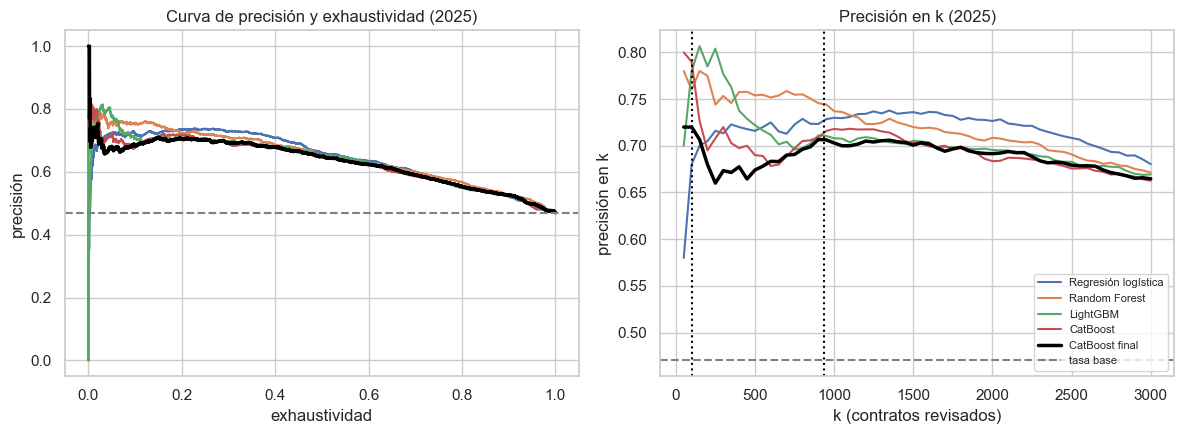


CatBoost final, alerta en el 10 % de mayor riesgo:
col_0        alerta  sin alerta   All
y                                    
con adición     664        3738  4402
sin adición     273        4688  4961
All             937        8426  9363


In [8]:
prueba = datos[datos["anio"] == PRUEBA]
finales, probs = {}, {}
for m in MODELOS:
    pipe_m, finales[NOMBRES[m]] = entrenar(
        m, params=mejores[m], evalua=PRUEBA, datos=datos)
    probs[NOMBRES[m]] = pipe_m.predict_proba(prueba[VARIABLES])[:, 1]
etiqueta_final = f"{NOMBRES[GANADOR['modelo']]} final"
final, finales[etiqueta_final] = entrenar(
    GANADOR["modelo"], evalua=PRUEBA, datos=datos, **FINAL)
p_final = final.predict_proba(prueba[VARIABLES])[:, 1]
probs[etiqueta_final] = p_final
print(pd.DataFrame(finales).T[PRINCIPALES + ["tasa_base"]].to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
k = np.arange(50, 3001, 50)
for nombre, p in probs.items():
    estilo = {"lw": 2.5, "color": "black"} if nombre == etiqueta_final else {}
    precision, recall, _ = precision_recall_curve(prueba["y"], p)
    ax[0].plot(recall, precision, label=nombre, **estilo)
    orden = prueba["y"].to_numpy()[np.argsort(-p, kind="stable")]
    ax[1].plot(k, [orden[:i].mean() for i in k], label=nombre, **estilo)
for eje in ax:
    eje.axhline(prueba["y"].mean(), ls="--", color="gray",
                label="tasa base")
ax[0].set(xlabel="exhaustividad", ylabel="precisión",
          title="Curva de precisión y exhaustividad (2025)")
ax[1].axvline(100, ls=":", color="black")
ax[1].axvline(round(0.1 * len(prueba)), ls=":", color="black")
ax[1].set(xlabel="k (contratos revisados)", ylabel="precisión en k",
          title="Precisión en k (2025)")
ax[1].legend(fontsize=8)
guardar_figura("14_prueba_2025")

alerta = p_final >= np.quantile(p_final, 0.9)
print(f"\n{etiqueta_final}, alerta en el 10 % de mayor riesgo:")
print(pd.crosstab(prueba["y"].map({0: "sin adición", 1: "con adición"}),
                  pd.Series(alerta, index=prueba.index).map(
                      {False: "sin alerta", True: "alerta"}),
                  margins=True).to_string())

## 9. Interpretabilidad

1. Importancia por permutación del modelo final en 2025.
2. Valores SHAP agrupados por variable original para 1.000 contratos de 2025,
   con 300 contratos de entrenamiento como referencia. Es la misma función
   que alimenta el panel I del tablero (`explicar`).
3. Ejemplo local: los cinco factores del contrato con mayor riesgo de la
   muestra.

 37%|=======             | 373/1000 [00:11<00:18]       

 41%|========            | 408/1000 [00:12<00:17]       

 45%|=========           | 448/1000 [00:13<00:16]       

 48%|==========          | 479/1000 [00:14<00:15]       

 52%|==========          | 515/1000 [00:15<00:14]       

 55%|===========         | 554/1000 [00:16<00:12]       

... (8 outputs left out)

 88%|==================  | 875/1000 [00:25<00:03]       

 91%|==================  | 912/1000 [00:26<00:02]       

 95%|=================== | 951/1000 [00:27<00:01]       

 99%|===================| 987/1000 [00:28<00:00]       

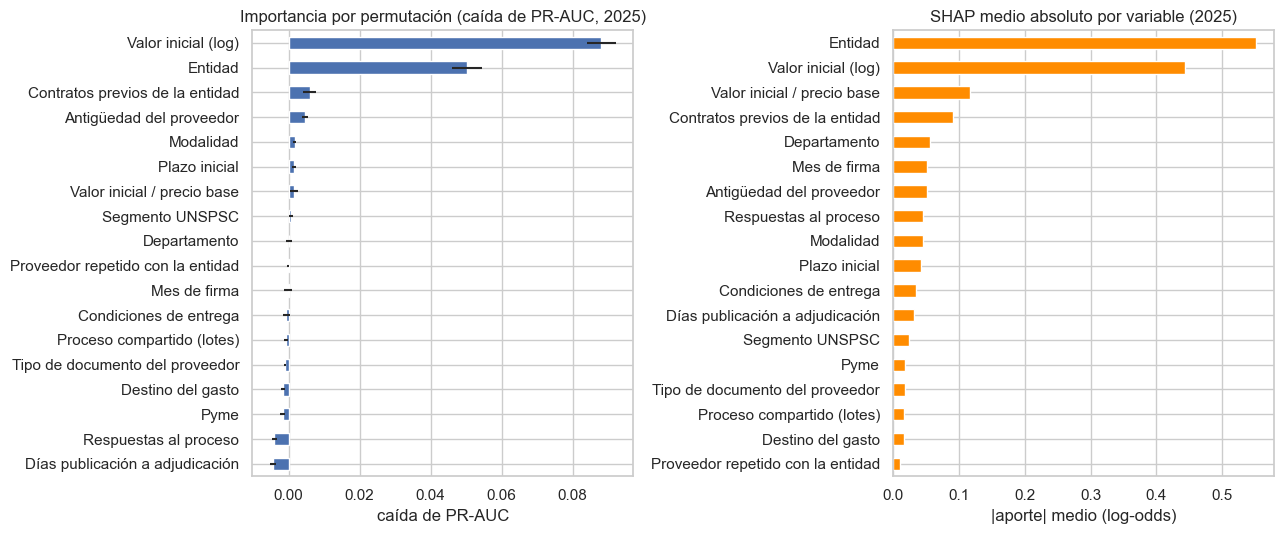

                                   media  desviación
Valor inicial (log)                0.088       0.004
Entidad                            0.050       0.004
Contratos previos de la entidad    0.006       0.002
Antigüedad del proveedor           0.005       0.001
Modalidad                          0.002       0.001
Plazo inicial                      0.002       0.001
Valor inicial / precio base        0.002       0.001
Segmento UNSPSC                    0.001       0.001
Departamento                       0.000       0.001
Proveedor repetido con la entidad -0.000       0.000
Mes de firma                      -0.000       0.001
Condiciones de entrega            -0.001       0.001
Proceso compartido (lotes)        -0.001       0.001
Tipo de documento del proveedor   -0.001       0.000
Destino del gasto                 -0.002       0.001
Pyme                              -0.002       0.001
Respuestas al proceso             -0.004       0.001
Días publicación a adjudicación   -0.004      

In [9]:
usadas = [v for v in VARIABLES if v not in GANADOR["excluir"]]
imp = permutation_importance(
    final, prueba[VARIABLES], prueba["y"], scoring="average_precision",
    n_repeats=5, random_state=SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"media": imp.importances_mean,
                            "desviación": imp.importances_std},
                           index=VARIABLES).loc[usadas].sort_values("media")

entrena = datos[datos["anio"] < PRUEBA]
fondo = entrena.sample(300, random_state=SEMILLA)
muestra = prueba.sample(1000, random_state=SEMILLA)
valores = aportes(final, muestra[VARIABLES], fondo[VARIABLES])
shap_global = valores.abs().mean().sort_values()

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
importancia.rename(index=ETIQUETAS)["media"].plot.barh(
    xerr=importancia["desviación"].to_numpy(), ax=ax[0])
ax[0].set(title="Importancia por permutación (caída de PR-AUC, 2025)",
          xlabel="caída de PR-AUC")
shap_global.rename(index=ETIQUETAS).plot.barh(ax=ax[1], color="darkorange")
ax[1].set(title="SHAP medio absoluto por variable (2025)",
          xlabel="|aporte| medio (log-odds)")
guardar_figura("15_importancia")
print(importancia.sort_values("media", ascending=False)
      .rename(index=ETIQUETAS).round(4).to_string())

riesgo = final.predict_proba(muestra[VARIABLES])[:, 1]
i = int(np.argmax(riesgo))
local = valores.iloc[i]
top = local.reindex(local.abs().sort_values(ascending=False).index[:5])
print(f"\nContrato {muestra['id_contrato'].iloc[i]}: probabilidad "
      f"{riesgo[i]:.2f}, adición real = {muestra['y'].iloc[i]}")
print(pd.DataFrame({"valor": muestra[top.index].iloc[i],
                    "aporte (log-odds)": top})
      .rename(index=ETIQUETAS).to_string())

## 10. Calibración y análisis de errores

1. Se compara la probabilidad media estimada con la tasa observada y se
   grafica la curva de calibración por deciles en 2024 (modelo entrenado con
   2019 a 2023) y en 2025 (modelo final).
2. Se revisa la alerta del 10 % de mayor riesgo por modalidad, tipo de
   documento del proveedor y departamento: proporción de contratos en alerta y
   precisión de la alerta. Siguiendo a Reina Hidalgo (2026), se vigila que
   ningún grupo concentre alertas sin respaldo en su tasa real.

2024: probabilidad media 0.286 | tasa observada 0.349 | Brier 0.204 | Brier de la tasa constante 0.227
2025: probabilidad media 0.302 | tasa observada 0.470 | Brier 0.256 | Brier de la tasa constante 0.249


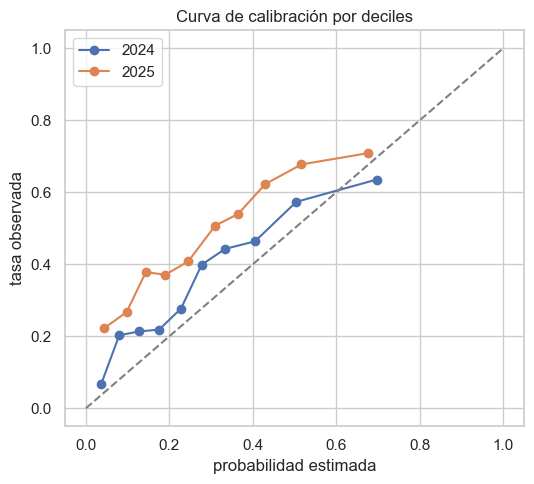


Modalidad (n >= 200):
                    contratos  tasa real  % en alerta  precisión de la alerta
modalidad                                                                    
Menor cuantía            2840      0.506        0.088                   0.721
Directa                  2436      0.417        0.083                   0.510
Mínima cuantía           1799      0.313        0.014                   0.520
Licitación pública       1168      0.759        0.307                   0.813
Régimen especial         1120      0.446        0.089                   0.750

Tipo de documento del proveedor (n >= 200):
                      contratos  tasa real  % en alerta  precisión de la alerta
tipodocproveedor                                                               
NIT                        7711      0.467        0.101                   0.699
Cédula de Ciudadanía       1111      0.407        0.054                   0.617

Departamento (n >= 200):
                            contratos  t

In [10]:
modelo_2024, _ = entrenar(GANADOR["modelo"], evalua=2024, datos=datos,
                          **FINAL)
valida = datos[datos["anio"] == 2024]
p_2024 = modelo_2024.predict_proba(valida[VARIABLES])[:, 1]

fig, ax = plt.subplots(figsize=(5.5, 5))
for nombre, y_real, p in [("2024", valida["y"], p_2024),
                          ("2025", prueba["y"], p_final)]:
    observada, estimada = calibration_curve(y_real, p, n_bins=10,
                                            strategy="quantile")
    ax.plot(estimada, observada, marker="o", label=nombre)
    print(f"{nombre}: probabilidad media {p.mean():.3f} | tasa observada "
          f"{y_real.mean():.3f} | Brier {np.mean((p - y_real) ** 2):.3f} "
          f"| Brier de la tasa constante "
          f"{y_real.mean() * (1 - y_real.mean()):.3f}")
ax.plot([0, 1], [0, 1], ls="--", color="gray")
ax.set(xlabel="probabilidad estimada", ylabel="tasa observada",
       title="Curva de calibración por deciles")
ax.legend()
guardar_figura("16_calibracion")

errores = prueba.assign(alerta=alerta)


def por_segmento(variable, minimo=200):
    g = errores.groupby(variable)
    t = pd.DataFrame({
        "contratos": g.size(), "tasa real": g["y"].mean(),
        "% en alerta": g["alerta"].mean(),
        "precisión de la alerta":
            errores[errores["alerta"]].groupby(variable)["y"].mean(),
    })
    return t[t["contratos"] >= minimo].sort_values("contratos",
                                                   ascending=False)


for variable in ["modalidad", "tipodocproveedor", "departamento"]:
    print(f"\n{ETIQUETAS[variable]} (n >= 200):")
    print(por_segmento(variable).to_string())

## 11. Modelos por tipo de adición

1. La configuración final se entrena también para `y_tiempo` e `y_valor`, que
   alimentan las dos probabilidades del tablero (elemento H).
2. Se reporta la validación temporal y la prueba en 2025 frente a la tasa
   base de cada objetivo.

In [11]:
filas = {}
for obj in OBJETIVOS:
    v = validar(GANADOR["modelo"], obj, datos=datos, **FINAL)
    _, t = entrenar(GANADOR["modelo"], obj, evalua=PRUEBA, datos=datos,
                    **FINAL)
    filas[obj] = {"PR-AUC validación": v["pr_auc"].mean(),
                  "tasa base validación": v["tasa_base"].mean(),
                  "PR-AUC prueba": t["pr_auc"],
                  "tasa base prueba": t["tasa_base"],
                  "AUC-ROC prueba": t["roc_auc"],
                  "precisión en 100": t["precision_100"],
                  "precisión top 10 %": t["precision_10pct"],
                  "lift top 10 %": t["lift_10pct"]}
print(pd.DataFrame(filas).T.to_string())

          PR-AUC validación  tasa base validación  PR-AUC prueba  tasa base prueba  AUC-ROC prueba  precisión en 100  precisión top 10 %  lift top 10 %
y                     0.524                 0.328          0.630             0.470           0.683             0.720               0.709          1.509
y_tiempo              0.493                 0.253          0.594             0.425           0.687             0.600               0.684          1.609
y_valor               0.224                 0.094          0.200             0.079           0.715             0.350               0.236          3.004


## 12. Modelo final

El modelo final se guarda para los tres objetivos con
`python src/modelo.py --ganador`, que entrena con 2019 a 2024, imprime las
métricas de prueba de las secciones 8 y 11 y escribe
`models/modelo_{objetivo}.joblib`. El tablero lo consume con `predecir` y
`explicar` (guía en `docs/modelos.md`).

## 13. Conclusiones